# LAB 3 — NHẬN DẠNG TIẾNG NÓI NÂNG CAO VỚI HMM
**Lỗ Anh Việt — 2351260695 — CSE457**

Nhận dạng 5 lệnh **mở, đóng, lên, xuống, dừng** theo case study trong PDF.
Chạy **Restart Kernel → Run All** trong môi trường của dự án. Notebook gọi mã trong
`lab3.py`; hình ở `figures/`, model ở `models/`, bảng CSV và báo cáo Markdown ở thư mục gốc.

**Dữ liệu:** 40 WAV tổng hợp TTS giọng NamMinh, 6 train + 2 test mỗi lệnh,
mono/16 kHz/PCM16 và silence đầu/cuối 0,2–0,5 giây. Nguồn/setting/hash được ghi
trong `dataset/manifest.json`. Cùng engine/giọng ở train/test; đây là kiểm chứng
pipeline trên TTS, chưa đại diện nhận dạng người nói thật.

`lexicon.txt` đang chờ phone inventory của giảng viên. Corpus LM tự tạo chỉ để minh
họa; các previous-word context không phải context đã ghi nhận trong test.

## 1. Môi trường và giao thức đánh giá

Baseline được định trước: 5 state, diagonal covariance, 39-D và CMVN theo utterance.
Không chọn model cuối bằng test accuracy. Các ablation dùng cùng split và được báo
cáo mô tả. Mỗi utterance là một yêu cầu TTS riêng với setting rate/pitch định trước;
train/test cùng giọng, không gọi là speaker-independent. SHA-256 và decoded-audio
hash kiểm tra trùng train/test; không đảm bảo sự độc lập như bản ghi người thật.

Cài đặt ở terminal: `uv venv --python 3.12 .venv`, sau đó
`uv pip install --python .venv/bin/python -r requirements-lock.txt`.

In [1]:
from pathlib import Path
import inspect
import json
import sys
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown, Code, Audio

ROOT = Path.cwd()
if not (ROOT / 'lab3.py').exists():
    raise RuntimeError('Mở notebook từ thư mục gốc Lab03 có lab3.py.')
sys.path.insert(0, str(ROOT))
from lab3 import (Config, VI, read_dataset, load_audio, extract_array, extract_features,
    make_lr_hmm, fit_models, check_topology, acoustic_scores, recognize,
    diag_log_emission, forward_backward, parse_lexicon, build_lm, bigram_prob, rerank, run_lab)

DATASET = ROOT / 'dataset'
OUT = ROOT
CONFIG = Config()
print('Python:', sys.version)
print(CONFIG)
labels, samples, audit, notices = read_dataset(DATASET)
display(pd.DataFrame(audit).groupby(['split', 'label']).size().unstack(fill_value=0))
for notice in notices:
    print('Lưu ý:', notice)

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Config(sr=16000, n_fft=512, win_length=400, hop_length=160, n_mfcc=13, n_mels=26, top_db=30.0, dynamic=True, n_states=5, covariance_type='diag', n_iter=80, tol=0.001, seed=695)


label,dong,dung,len,mo,xuong
split,,,,,
test,2,2,2,2,2
train,6,6,6,6,6


## 2. A — Trích đặc trưng MFCC + Δ + Δ²

WAV → mono/16 kHz → trim silence → pre-emphasis 0,97 → cửa sổ Hamming 25 ms,
hop 10 ms, FFT 512, 26 Mel → 13 MFCC + 13 delta + 13 delta-delta → CMVN.
Mỗi utterance có shape **T × 39**, T được giữ nguyên theo độ dài âm thanh.
Delta ước lượng bằng hồi quy lân cận; file quá ngắn/không có tiếng bị từ chối.

CMVN theo utterance không học thống kê chung từ test. Thống kê của một file test
chỉ được dùng để biến đổi chính file đó giống như khi suy luận.

In [2]:
display(Code(inspect.getsource(extract_array), language='python'))
for sample in samples[:3]:
    F = extract_features(sample.path, CONFIG)
    print(sample.path.name, F.shape, 'finite:', np.isfinite(F).all())
    assert F.shape[1] == 39

def extract_array(y, config=Config(), return_parts=False):
    y = np.asarray(y, dtype=float)
    if y.ndim != 1 or not len(y) or not np.isfinite(y).all() or np.max(np.abs(y)) < 1e-8:
        raise ValueError("Tín hiệu phải là vector mono hữu hạn, có tiếng.")
    y, bounds = librosa.effects.trim(y, top_db=config.top_db, frame_length=400, hop_length=160)
    if len(y) < config.win_length:
        raise ValueError("Audio sau cắt silence ngắn hơn 25 ms; cần thu lại.")
    y = librosa.effects.preemphasis(y, coef=0.97)
    mfcc = librosa.feature.mfcc(y=y, sr=config.sr, n_mfcc=config.n_mfcc,
        n_fft=config.n_fft, win_length=config.win_length, hop_length=config.hop_length,
        window="hamming", n_mels=config.n_mels, fmin=20, fmax=config.sr / 2)
    # mode=nearest supports short words. Delta-delta is a second derivative.
    width = min(9, mfcc.shape[1] if mfcc.shape[1] % 2 else mfcc.shape[1] - 1)
    if width < 3:
        raise ValueError("Cần ít nhất 3 frame để tính delta.")
    d1 = librosa.feature.delta(mfcc, width=width, order=1, mode="nearest")
    d2 = librosa.feature.delta(mfcc, width=width, order=2, mode="nearest")
    raw = np.vstack([mfcc, d1, d2]).T if config.dynamic else mfcc.T
    # Per-utterance CMVN: no shared test statistics, same transform at inference.
    features = (raw - raw.mean(axis=0)) / np.maximum(raw.std(axis=0), 1e-3)
    if not np.isfinite(features).all():
        raise ValueError("Đặc trưng không hữu hạn.")
    if return_parts:
        return features, (mfcc, d1, d2), bounds
    return features

dong_namminh_01.wav (37, 39) finite: True
dong_namminh_02.wav (34, 39) finite: True
dong_namminh_03.wav (32, 39) finite: True


## 3. B–H — Chạy pipeline và lưu kết quả

Lệnh dưới chạy toàn bộ thí nghiệm: huấn luyện, likelihood, Viterbi, DTW, số state,
13/39-D, số mẫu train, nhiễu 20 dB, bigram và báo cáo Markdown.
Thời gian decode tách khỏi front-end; DTW đã warm-up JIT trước khi đo.

In [3]:
summary = run_lab(DATASET, OUT, ROOT / 'models', ROOT / 'corpus.txt', ROOT / 'lexicon.txt', CONFIG)
display(pd.Series(summary)[['train_count', 'test_count', 'train_accuracy',
    'test_accuracy', 'dtw_lab2_accuracy', 'dtw_shared_accuracy', 'noise_accuracy']])

Dữ liệu: 5 lớp, 30 train, 10 test


Trích MFCC 39-D...


Huấn luyện baseline 5-state...


Thí nghiệm E1_states3...


Thí nghiệm baseline_states5_39D...


...

So sánh DTW dùng chung front-end và mã Lab 2...


Thử số mẫu train và mismatch nhiễu...


Lexicon và bigram re-ranking...


Hoàn tất: HMM=100.0%, DTW Lab2=100.0%, noise=20.0%. Xem /home/viet/projects/TLU/XuLyAmThanh/ThucHanh/Lab03_2351260695_LoAnhViet


train_count             30
test_count              10
train_accuracy         1.0
test_accuracy          1.0
dtw_lab2_accuracy      1.0
dtw_shared_accuracy    1.0
noise_accuracy         0.2
dtype: object

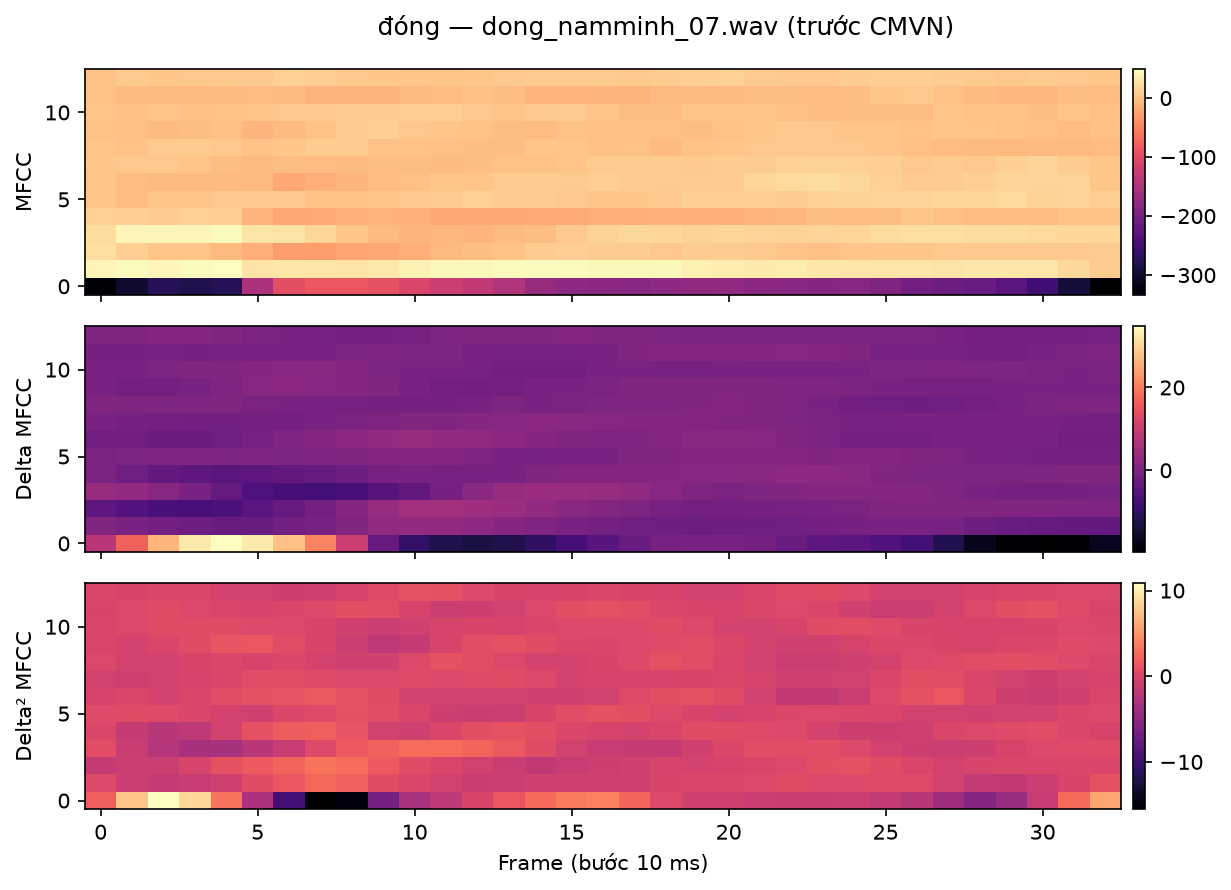

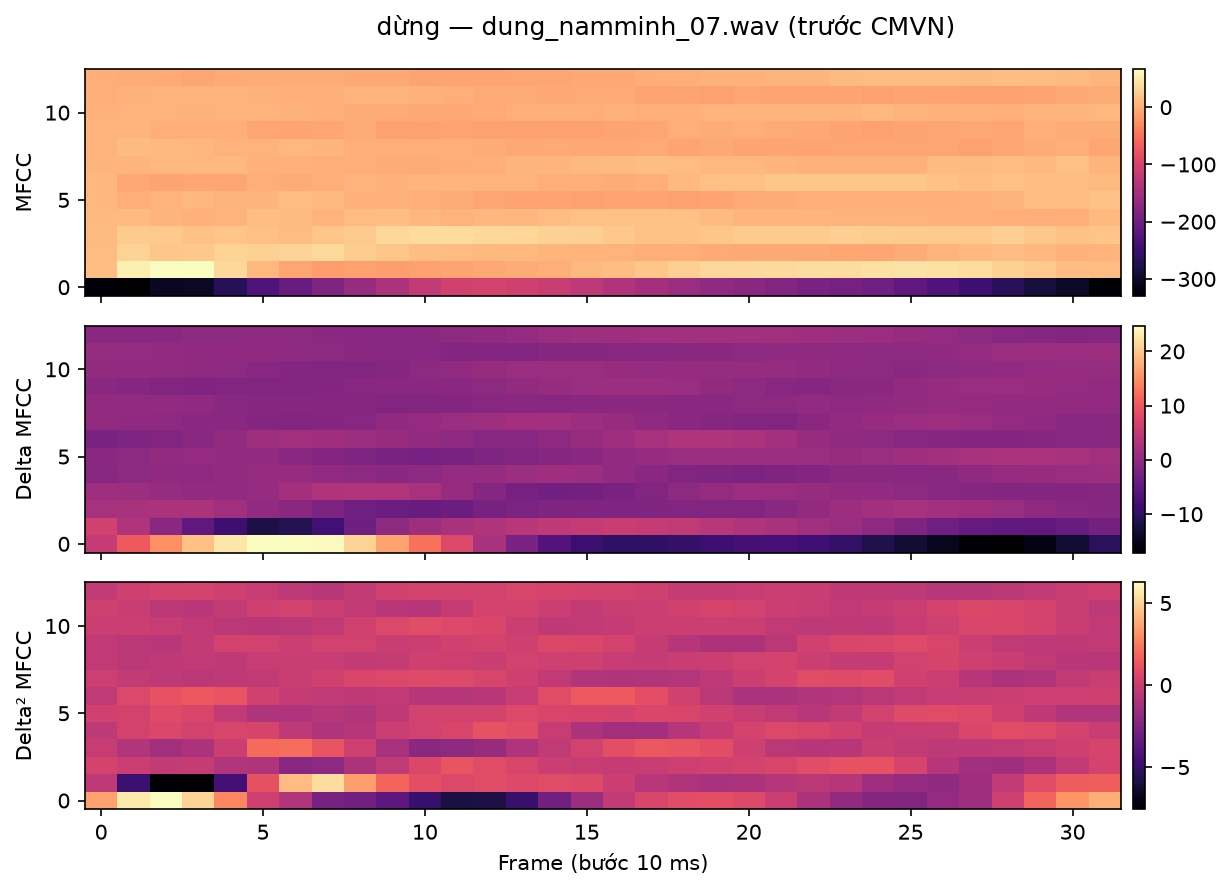

In [4]:
display(Image(filename=str(OUT / 'figures/features_1.png')))
display(Image(filename=str(OUT / 'figures/features_2.png')))

MFCC biểu diễn phổ; delta và delta-delta làm rõ chuyển động cục bộ quanh onset,
offset và các chuyển tiếp. Vị trí/số frame khác nhau phản ánh độ dài từng từ và cách
nói. Đọc hình cùng audio để nhận xét; không suy ra âm vị chỉ từ màu heatmap.

## 4. B–C — HMM trái-sang-phải và Baum–Welch

HMM gồm π (phân bố bắt đầu), A (chuyển trạng thái), B (mật độ Gaussian phát xạ).
π = [1,0,…,0]; A chỉ có self-loop/next-state, state cuối hấp thụ. Khởi tạo emission
bằng các phần thời gian liên tiếp của **train** để state có thứ tự âm học ban đầu.

`init_params=''` vì đã khởi tạo tất cả; `params='tmc'` chỉ cập nhật A, mean, covariance.
Các utterance cùng lớp được ghép, truyền `lengths` để không tạo chuyển trạng thái
giả giữa hai bản ghi. Sau fit kiểm tra π, tổng từng hàng A và các transition cấm.

def make_lr_hmm(sequences, config=Config()):
    """Temporal initialization keeps emissions ordered; fitted on train only."""
    if config.covariance_type not in ("diag", "full"):
        raise ValueError("Chỉ hỗ trợ diag/full.")
    if any(len(x) < config.n_states for x in sequences):
        raise ValueError("Utterance quá ngắn so với số state.")
    n, d = config.n_states, sequences[0].shape[1]
    model = GaussianHMM(n_components=n, covariance_type=config.covariance_type,
        n_iter=config.n_iter, tol=config.tol, min_covar=1e-3,
        init_params="", params="tmc", random_state=config.seed,
        implementation="log", covars_prior=0.01 if config.covariance_type == "diag" else np.eye(d) * 0.1,
        covars_weight=1 if config.covariance_type == "diag" else d + 2)
    model.startprob_ = np.eye(n)[0]
    model.transmat_ = lr_transition(n)
    pools = [np.vstack([np.array_split(x, n)[i] for x in sequences]) for i in range(n)]
    model.means_ = np.vstack([x.mean(axis=0) for x in pools])
    if config.covariance_type == "diag":
        model.covars_ = np.vstack([np.maximum(x.var(axis=0), 1e-2) for x in pools])
    else:
        model.covars_ = np.stack([np.atleast_2d(np.cov(x, rowvar=False)) + np.eye(d) * 0.1 for x in pools])
    model.monitor_ = TraceMonitor(config.tol, config.n_iter)
    return model

dong start: [1. 0. 0. 0. 0.]
[[0.86  0.14  0.    0.    0.   ]
 [0.    0.829 0.171 0.    0.   ]
 [0.    0.    0.85  0.15  0.   ]
 [0.    0.    0.    0.786 0.214]
 [0.    0.    0.    0.    1.   ]]
dung start: [1. 0. 0. 0. 0.]
[[0.864 0.136 0.    0.    0.   ]
 [0.    0.838 0.162 0.    0.   ]
 [0.    0.    0.824 0.176 0.   ]
 [0.    0.    0.    0.838 0.162]
 [0.    0.    0.    0.    1.   ]]
len start: [1. 0. 0. 0. 0.]
[[0.893 0.107 0.    0.    0.   ]
 [0.    0.76  0.24  0.    0.   ]
 [0.    0.    0.85  0.15  0.   ]
 [0.    0.    0.    0.818 0.182]
 [0.    0.    0.    0.    1.   ]]
mo start: [1. 0. 0. 0. 0.]
[[0.87  0.13  0.    0.    0.   ]
 [0.    0.793 0.207 0.    0.   ]
 [0.    0.    0.906 0.094 0.   ]
 [0.    0.    0.    0.834 0.166]
 [0.    0.    0.    0.    1.   ]]
xuong start: [1. 0. 0. 0. 0.]
[[0.867 0.133 0.    0.    0.   ]
 [0.    0.833 0.167 0.    0.   ]
 [0.    0.    0.842 0.158 0.   ]
 [0.    0.    0.    0.785 0.215]
 [0.    0.    0.    0.    1.   ]]


,label,utterances,frames,iterations,stop_reason,last_gain
0,dong,6,191,14,tolerance,0.000133
1,dung,6,185,13,tolerance,0.000002
2,len,6,196,19,tolerance,0.000727
3,mo,6,220,11,likelihood_decreased,-0.000034
4,xuong,6,194,10,tolerance,0.000818


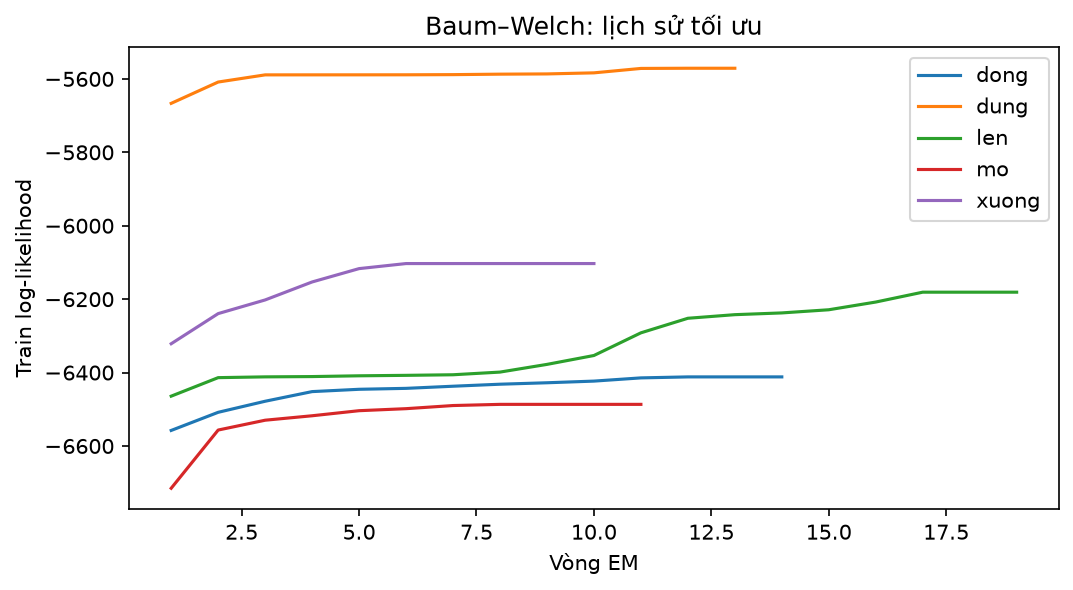

In [5]:
display(Code(inspect.getsource(make_lr_hmm), language='python'))
payload = joblib.load(ROOT / 'models/hmm_baseline.joblib')
models = payload['models']
for label, model in models.items():
    check_topology(model)
    print(label, 'start:', model.startprob_)
    print(np.round(model.transmat_, 3))
diagnostics = json.loads((OUT / 'training_diagnostics.json').read_text())
display(pd.DataFrame(diagnostics)[['label', 'utterances', 'frames', 'iterations', 'stop_reason', 'last_gain']])
display(Image(filename=str(OUT / 'figures/convergence.png')))

Diagonal covariance có 39 phương sai/state; full covariance có 780 phần tử độc lập
cho D=39. Với ít dữ liệu, ước lượng full dễ bất ổn. `monitor.converged` có thể True
khi hết số vòng lặp; cần đọc gain cuối và lý do dừng. Baum–Welch là EM và chỉ tìm
nghiệm cục bộ, phụ thuộc khởi tạo, số state, lượng dữ liệu và độ khớp môi trường.

## 5. D — Likelihood, Forward, Viterbi và trách nhiệm EM

Forward dùng tổng qua mọi đường để tính likelihood. Viterbi dùng max để tìm đường
trạng thái tốt nhất. Trong miền log, tổng xác suất là `logsumexp`.

γₜ(i) = P(qₜ=i | X): trách nhiệm state i cho frame t.
ξₜ(i,j) = P(qₜ=i, qₜ₊₁=j | X): trách nhiệm chuyển i→j tại t.
Forward–Backward bên dưới minh họa E-step; không tự thay thế Baum–Welch của thư viện.

In [6]:
display(Code(inspect.getsource(forward_backward), language='python'))
test_samples = [s for s in samples if s.split == 'test']
s = test_samples[0]
F = extract_features(s.path, CONFIG)
scores = acoustic_scores(F, models)
display(pd.DataFrame({'label': list(scores), 'log_likelihood': list(scores.values())}))
ll, gamma, xi_sum = forward_backward(diag_log_emission(F, models[s.label]),
    models[s.label].startprob_, models[s.label].transmat_)
viterbi_logp, states = models[s.label].decode(F, algorithm='viterbi')
assert np.isclose(ll, models[s.label].score(F), atol=1e-6)
assert ll >= viterbi_logp - 1e-6
assert np.allclose(gamma.sum(axis=1), 1)
assert np.isclose(xi_sum.sum(), len(F) - 1)
print('Forward:', ll, 'Viterbi:', viterbi_logp)
print('Prediction:', max(scores, key=scores.get), '| reference:', s.label)
display(pd.read_csv(OUT / 'likelihood_examples.csv'))

def forward_backward(log_emission, start, transitions):
    """Educational log-domain Forward/Backward, gamma and summed xi; no training."""
    b, a, pi = np.asarray(log_emission), safe_log(transitions), safe_log(start)
    T, n = b.shape
    alpha = np.empty((T, n))
    alpha[0] = pi + b[0]
    for t in range(1, T):
        alpha[t] = b[t] + logsumexp(alpha[t - 1, :, None] + a, axis=0)
    ll = float(logsumexp(alpha[-1]))
    if not np.isfinite(ll):
        raise ValueError("Không có đường trạng thái hợp lệ.")
    beta = np.zeros((T, n))
    for t in range(T - 2, -1, -1):
        beta[t] = logsumexp(a + b[t + 1][None, :] + beta[t + 1][None, :], axis=1)
    gamma = np.exp(alpha + beta - ll)
    xi_sum = np.zeros((n, n))
    for t in range(T - 1):
        xi_sum += np.exp(alpha[t, :, None] + a + b[t + 1][None, :] + beta[t + 1][None, :] - ll)
    return ll, gamma, xi_sum

,label,log_likelihood
0,dong,-1106.281391
1,dung,-4249.882458
2,len,-3645.161277
3,mo,-3703.423019
4,xuong,-3385.187900


Forward: -1106.2813906815327 Viterbi: -1106.3524967295837
Prediction: dong | reference: dong


,file,true_label,prediction,correct,frames,top2,margin_per_frame,best_score_per_frame,score_dong,score_dung,score_len,score_mo,score_xuong
0,test/dong/dong_namminh_07.wav,dong,dong,True,33,xuong,69.057773,-33.523679,-1106.281391,-4249.882458,-3645.161277,-3703.423019,-3385.187900
1,test/dung/dung_namminh_07.wav,dung,dung,True,32,len,54.542584,-31.198469,-2965.870382,-998.350998,-2743.713694,-4085.283552,-3545.547032
2,test/len/len_namminh_07.wav,len,len,True,34,dong,57.210869,-35.472857,-3151.246673,-3215.920410,-1206.077144,-3890.491800,-4272.820944


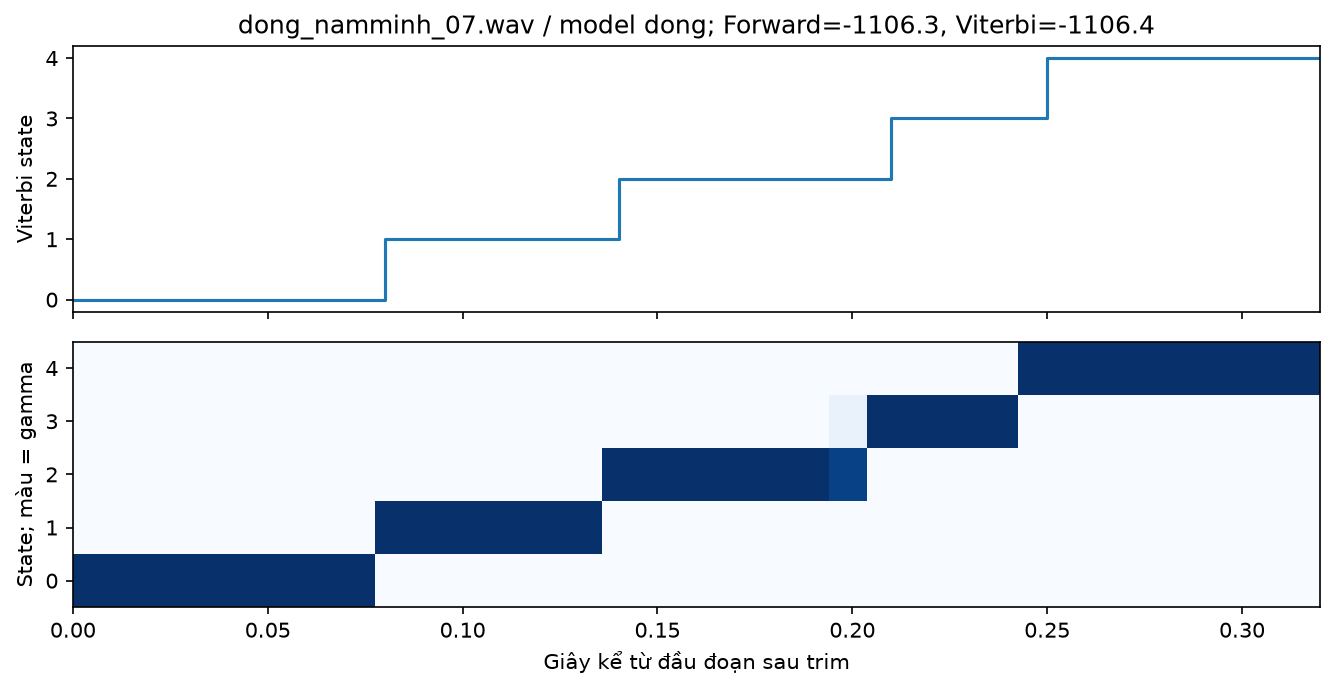

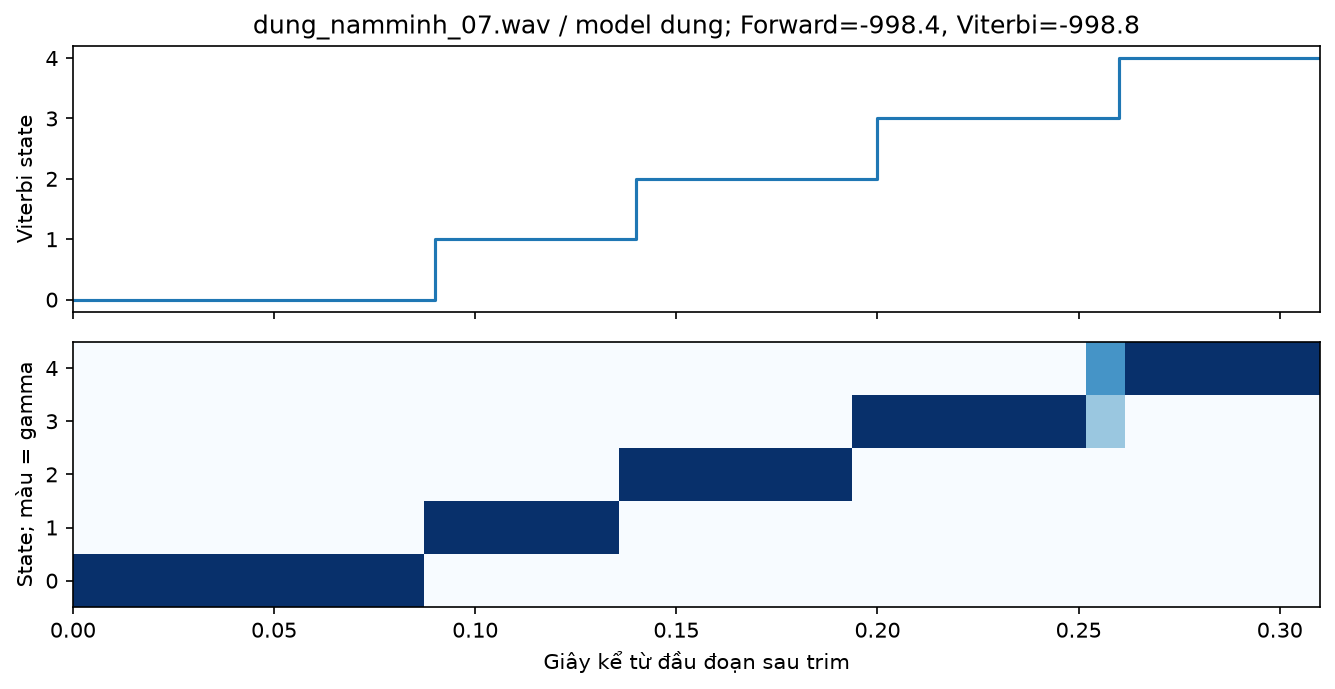

,file,label,state,frames,occupancy_ms_approx,trim_start_sample,forward_logp,viterbi_logp
0,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dong,0,8,80,4960,-1106.281391,-1106.352497
1,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dong,1,6,60,4960,-1106.281391,-1106.352497
2,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dong,2,7,70,4960,-1106.281391,-1106.352497
3,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dong,3,4,40,4960,-1106.281391,-1106.352497
4,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dong,4,8,80,4960,-1106.281391,-1106.352497
5,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dung,0,9,90,5760,-998.350998,-998.840803
6,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dung,1,5,50,5760,-998.350998,-998.840803
7,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dung,2,6,60,5760,-998.350998,-998.840803
8,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dung,3,6,60,5760,-998.350998,-998.840803
9,/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/L...,dung,4,6,60,5760,-998.350998,-998.840803


In [7]:
display(Image(filename=str(OUT / 'figures/viterbi_1.png')))
display(Image(filename=str(OUT / 'figures/viterbi_2.png')))
display(pd.read_csv(OUT / 'state_durations.csv'))

Self-loop biểu diễn duration ngầm: nói chậm có thể tăng số frame giữ cùng state.
Occupancy xấp xỉ số frame × 10 ms. HMM này không bắt buộc mọi utterance đi tới state
cuối; tổng likelihood kết thúc ở mọi state như công thức trong đề. State chưa được
giám sát theo phoneme nên không được gán tên âm vị cụ thể.

## 6. E — Đánh giá và so sánh DTW

DTW Lab 2 giữ front-end cũ: endpoint adaptive, 24 Mel, 13 MFCC và CMN; mã nằm ở
`lab2_baseline.py`. DTW chung front-end dùng cùng 39-D/CMVN như HMM. Cả hai lấy min
distance qua tất cả template train, chuẩn hóa tổng chi phí theo độ dài đường DTW.
Recurrence đã được đối chiếu với mã gốc. Các phương pháp dùng đúng cùng train/test.

,method,train_accuracy,test_accuracy,model_fit_seconds,frontend_seconds_per_file,decode_seconds_per_trial
0,HMM_39D,1.0,1.0,0.064892,0.001055,0.000495
1,DTW_shared_39D,NaN,1.0,0.000007,0.001055,0.000509
2,DTW_Lab2_13D,NaN,1.0,0.000012,0.001270,0.002363


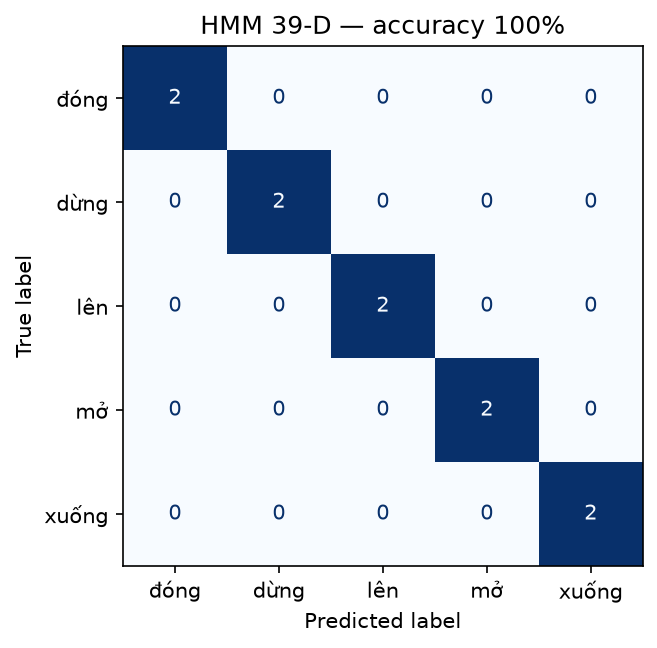

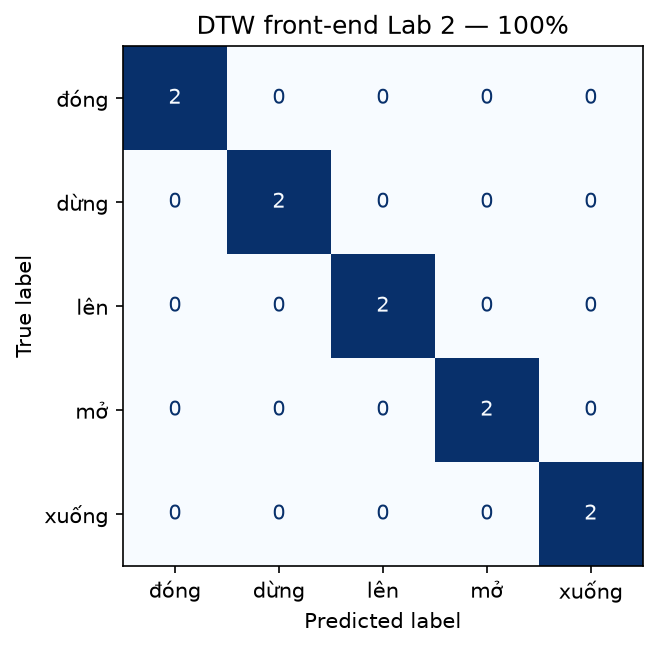

,file,truth,hmm,dtw_shared,dtw_lab2,hmm_correct,dtw_correct
0,test/dong/dong_namminh_07.wav,dong,dong,dong,dong,True,True
1,test/dong/dong_namminh_08.wav,dong,dong,dong,dong,True,True
2,test/dung/dung_namminh_07.wav,dung,dung,dung,dung,True,True
3,test/dung/dung_namminh_08.wav,dung,dung,dung,dung,True,True
4,test/len/len_namminh_07.wav,len,len,len,len,True,True
5,test/len/len_namminh_08.wav,len,len,len,len,True,True
6,test/mo/mo_namminh_07.wav,mo,mo,mo,mo,True,True
7,test/mo/mo_namminh_08.wav,mo,mo,mo,mo,True,True
8,test/xuong/xuong_namminh_07.wav,xuong,xuong,xuong,xuong,True,True
9,test/xuong/xuong_namminh_08.wav,xuong,xuong,xuong,xuong,True,True


Chưa có trường hợp khác nhau về đúng/sai; cần thêm test.

,train_per_class,hmm_accuracy,dtw_shared_accuracy
0,1,1.0,1.0
1,2,1.0,1.0
2,6,1.0,1.0


In [8]:
display(pd.read_csv(OUT / 'dtw_vs_hmm.csv'))
display(Image(filename=str(OUT / 'figures/confusion_hmm.png')))
display(Image(filename=str(OUT / 'figures/confusion_dtw_lab2.png')))
comparison_cases = pd.read_csv(OUT / 'comparison_cases.csv')
display(comparison_cases)
different = comparison_cases[comparison_cases.hmm_correct != comparison_cases.dtw_correct]
display(different if len(different) else Markdown('Chưa có trường hợp khác nhau về đúng/sai; cần thêm test.'))
display(pd.read_csv(OUT / 'training_sizes.csv'))

DTW lưu template, xử lý biến thiên bằng warping; HMM học phân bố và duration qua
transition, cần dữ liệu để ước lượng tham số. HMM có thể khái quát từ nhiều bản ghi;
DTW có thể thuận lợi khi ít mẫu và test gần template. Ví dụ lỗi trong bảng là quan
sát, chưa đủ để xác định nguyên nhân; nên nghe lại trước khi giải thích.

## 7. E1–E3 — Kiểm soát số state và đặc trưng

Thay một biến mỗi lần, giữ split/seed/front-end còn lại cố định. 13-D là chính phần
MFCC tĩnh của 39-D, nên đối chiếu đặc trưng không đổi chuẩn hóa. Full covariance
chỉ chạy nếu tối thiểu mỗi lớp đủ 2 × D × n_states frame; nếu không thì ghi skipped.
Đây là tiêu chí thận trọng của bài triển khai, không phải định lý đủ dữ liệu.

In [9]:
experiments = pd.read_csv(OUT / 'experiments.csv')
display(experiments)
baseline_accuracy = experiments.loc[experiments.experiment == 'baseline_states5_39D', 'test_accuracy'].iloc[0]
static_accuracy = experiments.loc[experiments.experiment == 'E2_mfcc13', 'test_accuracy'].iloc[0]
print(f'39-D trừ 13-D: {(baseline_accuracy - static_accuracy) * 100:.0f} điểm phần trăm trên test hiện tại.')

,experiment,states,dimensions,covariance,train_accuracy,test_accuracy,max_iter_models,status
0,E1_states3,3,39,diag,1.0,1.0,0.0,ok
1,baseline_states5_39D,5,39,diag,1.0,1.0,0.0,ok
2,E1_states7,7,39,diag,1.0,1.0,1.0,ok
3,E2_mfcc13,5,13,diag,1.0,1.0,0.0,ok
4,E3_full,5,39,full,NaN,NaN,NaN,skipped: quá ít frame/state so với D=39; E3 ch...


39-D trừ 13-D: 0 điểm phần trăm trên test hiện tại.


## 8. F — Lexicon mini

Whole-word HMM ánh xạ nhãn trực tiếp sang model nên không cần pronunciation lexicon
để nhận dạng. Với subword HMM, từ được tạo bằng cách nối phone HMM theo lexicon.
Chưa có inventory của giảng viên: giữ `lexicon.txt` là template chú thích, không tự
đặt phiên âm rồi coi là chuẩn. Parser được kiểm thử bằng inventory giả trong tests.

In [10]:
lexicon = parse_lexicon(ROOT / 'lexicon.txt')
print('Lexicon hiện tại:', lexicon)
print('Các từ cần phone sequence từ giảng viên:', sorted(set(labels) - set(lexicon)))
display(Code(inspect.getsource(parse_lexicon), language='python'))

Lexicon hiện tại: {}
Các từ cần phone sequence từ giảng viên: ['dong', 'dung', 'len', 'mo', 'xuong']


def parse_lexicon(path):
    lexicon = {}
    for number, line in enumerate(Path(path).read_text(encoding="utf-8").splitlines(), 1):
        tokens = line.partition("#")[0].strip().split()
        if not tokens:
            continue
        if len(tokens) < 2 or tokens[0] in lexicon:
            raise ValueError(f"Lexicon dòng {number}: thiếu phone hoặc từ trùng.")
        lexicon[tokens[0]] = tokens[1:]
    return lexicon

## 9. G — Unigram, bigram và MAP re-ranking

Corpus tự tạo trong `corpus.txt`, không lấy nhãn test làm corpus.
P(w|prev) = [C(prev,w)+k] / [C_out(prev)+kV], k=0,5.
`C_out` chỉ đếm context có từ kế tiếp trong vocabulary. Không đưa `</s>` vào mẫu số
nếu `</s>` không thuộc tập ứng viên; mỗi dòng độc lập, có context bắt đầu `<s>`.

Score(w) = log P(X|w)/T + λ log P(w|prev). Thử λ=0; 0,1; 0,3; 1,0 trên ba file có
margin âm học nhỏ nhất, liệt kê mọi previous-word context để tránh suy ngữ cảnh từ
nhãn thật. Đây là phân tích giả định, không báo accuracy LM trên chuỗi nói thực.

In [11]:
lm = build_lm(ROOT / 'corpus.txt', labels)
for previous in ['<s>'] + labels:
    assert np.isclose(sum(bigram_prob(lm, previous, w) for w in labels), 1)
display(pd.read_csv(OUT / 'unigram_counts.csv'))
reranking = pd.read_csv(OUT / 'lm_reranking.csv')
changed = reranking[reranking.changed]
display(changed if len(changed) else reranking.head(12))
print('Số tình huống giả định đổi quyết định:', len(changed))
print('Không gộp những tình huống này thành accuracy của một test set có context thật.')

,word,count
0,dong,8
1,dung,10
2,len,6
3,mo,8
4,xuong,4


,file,true_label,previous,context_source,lm_weight,acoustic_prediction,prediction,changed,correct,total_dong,total_dung,total_len,total_mo,total_xuong
0,test/xuong/xuong_namminh_08.wav,xuong,<s>,hypothetical_not_observed,0.0,xuong,xuong,False,True,-72.386577,-113.942784,-117.462464,-134.361952,-32.479505
1,test/xuong/xuong_namminh_08.wav,xuong,<s>,hypothetical_not_observed,0.1,xuong,xuong,False,True,-72.547520,-114.264671,-117.674490,-134.427344,-32.691531
2,test/xuong/xuong_namminh_08.wav,xuong,<s>,hypothetical_not_observed,0.3,xuong,xuong,False,True,-72.869408,-114.908446,-118.098543,-134.558129,-33.115584
3,test/xuong/xuong_namminh_08.wav,xuong,<s>,hypothetical_not_observed,1.0,xuong,xuong,False,True,-73.996015,-117.161659,-119.582727,-135.015878,-34.599768
4,test/xuong/xuong_namminh_08.wav,xuong,dong,hypothetical_not_observed,0.0,xuong,xuong,False,True,-72.386577,-113.942784,-117.462464,-134.361952,-32.479505
5,test/xuong/xuong_namminh_08.wav,xuong,dong,hypothetical_not_observed,0.1,xuong,xuong,False,True,-72.606299,-114.162506,-117.682186,-134.420730,-32.699227
6,test/xuong/xuong_namminh_08.wav,xuong,dong,hypothetical_not_observed,0.3,xuong,xuong,False,True,-73.045744,-114.601951,-118.121631,-134.538288,-33.138672
7,test/xuong/xuong_namminh_08.wav,xuong,dong,hypothetical_not_observed,1.0,xuong,xuong,False,True,-74.583801,-116.140008,-119.659688,-134.949738,-34.676729
8,test/xuong/xuong_namminh_08.wav,xuong,dung,hypothetical_not_observed,0.0,xuong,xuong,False,True,-72.386577,-113.942784,-117.462464,-134.361952,-32.479505
9,test/xuong/xuong_namminh_08.wav,xuong,dung,hypothetical_not_observed,0.1,xuong,xuong,False,True,-72.441231,-114.237227,-117.647046,-134.656395,-32.664087


Số tình huống giả định đổi quyết định: 0
Không gộp những tình huống này thành accuracy của một test set có context thật.


λ=0 phải giữ nguyên acoustic argmax; λ lớn có thể giúp khi context phù hợp hoặc làm
sai khi context không phù hợp. Nếu không có thay đổi trong dải λ đang thử, báo đúng
quan sát đó, không tạo kết quả giả để minh họa ưu thế của LM.

## 10. H — Robustness và unknown/reject

Nhiễu Gaussian cộng vào tín hiệu trước trích đặc trưng, SNR 20 dB theo công suất phần
tiếng nói sau trim; seed cố định từng file. Không đưa nhiễu test vào fit.
Với từ ngoài vocabulary, argmax vẫn chọn một nhãn vì chỉ biết các model đã học.
Có thể reject khi score/frame thấp hoặc margin top-1/top-2 nhỏ.

Ngưỡng trong `reject_proposal.json` là gợi ý lấy phân vị 5% của các mẫu đúng trên
holdout train (một file/lớp); không hiệu chỉnh trên test và chưa dùng để đổi dự đoán
baseline. Vì quá ít calibration và final model được train lại với nhiều mẫu hơn,
cần validation độc lập cùng unknown thật trước khi áp dụng.

Clean: 1.0 Noise: 0.2


,method,clean_accuracy,noise_accuracy
0,HMM_39D,1.0,0.2
1,DTW_shared_39D,1.0,0.6
2,DTW_Lab2_13D,1.0,0.2


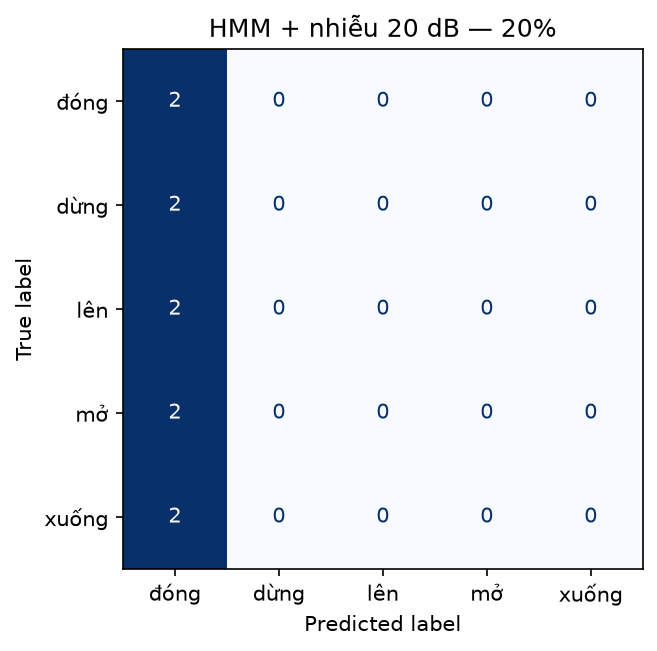

,file,clean_frames,noisy_frames,clean_trim_seconds,noisy_trim_seconds,input_seconds,true_label,prediction,states_visited,dominant_state_fraction,margin_per_frame
0,test/dong/dong_namminh_07.wav,33,105,0.32,1.044188,1.044188,dong,dong,"0,1,2",0.952381,24.806411
1,test/dong/dong_namminh_08.wav,29,128,0.28,1.279750,1.279750,dong,dong,0,1.000000,24.778515
2,test/dung/dung_namminh_07.wav,32,104,0.31,1.032437,1.032437,dung,dong,"0,1,2",0.961538,25.317562
3,test/dung/dung_namminh_08.wav,28,149,0.27,1.489625,1.489625,dung,dong,"0,1,2,3",0.946309,25.083794
4,test/len/len_namminh_07.wav,34,143,0.33,1.425563,1.425563,len,dong,"0,1,2",0.937063,24.895876
5,test/len/len_namminh_08.wav,30,140,0.29,1.396500,1.396500,len,dong,0,1.000000,24.778490
6,test/mo/mo_namminh_07.wav,39,141,0.38,1.401250,1.401250,mo,dong,0,1.000000,24.778488
7,test/mo/mo_namminh_08.wav,32,121,0.31,1.204687,1.204687,mo,dong,0,1.000000,24.778531
8,test/xuong/xuong_namminh_07.wav,34,219,0.33,2.184625,2.184625,xuong,dong,0,1.000000,24.778395
9,test/xuong/xuong_namminh_08.wav,29,142,0.28,1.418313,1.418313,xuong,dong,0,1.000000,24.778495


,file,truth,hmm,dtw_shared,dtw_lab2,hmm_correct,dtw_correct
0,test/dong/dong_namminh_07.wav,dong,dong,dong,xuong,True,True
1,test/dong/dong_namminh_08.wav,dong,dong,dong,xuong,True,True
2,test/dung/dung_namminh_07.wav,dung,dong,xuong,xuong,False,False
3,test/dung/dung_namminh_08.wav,dung,dong,xuong,xuong,False,False
4,test/len/len_namminh_07.wav,len,dong,mo,xuong,False,False
5,test/len/len_namminh_08.wav,len,dong,mo,xuong,False,False
6,test/mo/mo_namminh_07.wav,mo,dong,mo,xuong,False,True
7,test/mo/mo_namminh_08.wav,mo,dong,mo,xuong,False,True
8,test/xuong/xuong_namminh_07.wav,xuong,dong,xuong,xuong,False,True
9,test/xuong/xuong_namminh_08.wav,xuong,dong,xuong,xuong,False,True


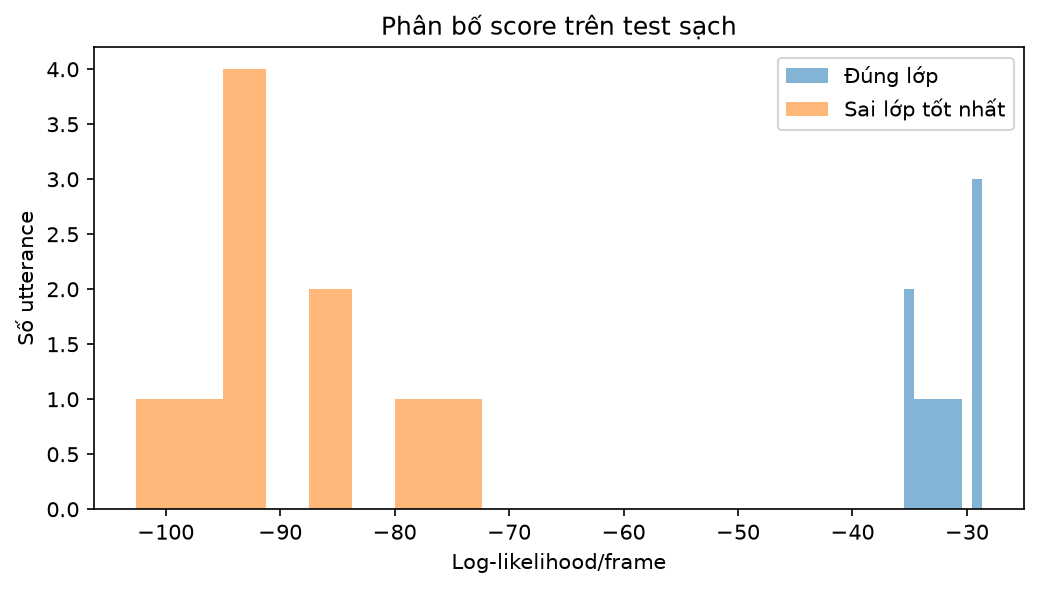

,condition,file,true_class_score_per_frame,best_wrong_class_score_per_frame
0,clean,test/dong/dong_namminh_07.wav,-33.523679,-102.581452
1,clean,test/dong/dong_namminh_08.wav,-34.825734,-97.950320
2,clean,test/dung/dung_namminh_07.wav,-31.198469,-85.741053
3,clean,test/dung/dung_namminh_08.wav,-28.714478,-85.004316
4,clean,test/len/len_namminh_07.wav,-35.472857,-92.683726
5,clean,test/len/len_namminh_08.wav,-34.570087,-92.197812
6,clean,test/mo/mo_namminh_07.wav,-29.353142,-92.684292
7,clean,test/mo/mo_namminh_08.wav,-29.466526,-91.470816
8,clean,test/xuong/xuong_namminh_07.wav,-31.652809,-77.852231
9,clean,test/xuong/xuong_namminh_08.wav,-32.479505,-72.386577


{'calibration_source': 'last train utterance/class held out; zero test used',
 'calibration_files': ['/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/Lab03_2351260695_LoAnhViet/dataset/train/dong/dong_namminh_06.wav',
  '/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/Lab03_2351260695_LoAnhViet/dataset/train/dung/dung_namminh_06.wav',
  '/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/Lab03_2351260695_LoAnhViet/dataset/train/len/len_namminh_06.wav',
  '/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/Lab03_2351260695_LoAnhViet/dataset/train/mo/mo_namminh_06.wav',
  '/home/viet/projects/TLU/XuLyAmThanh/ThucHanh/Lab03_2351260695_LoAnhViet/dataset/train/xuong/xuong_namminh_06.wav'],
 'validation_accuracy': 1.0,
 'correct_calibration_count': 5,
 'score_threshold': -33.84282581492621,
 'margin_threshold': 43.46749303204646,
 'status': 'proposal_only',
 'limitation': 'Rất ít validation; model train lại trên toàn train có thể đổi phân bố score. Cần validation/unknown độc lập trước khi áp dụng.'}

In [12]:
print('Clean:', summary['test_accuracy'], 'Noise:', summary['noise_accuracy'])
display(pd.read_csv(OUT / 'noise_methods.csv'))
display(Image(filename=str(OUT / 'figures/confusion_noise.png')))
display(pd.read_csv(OUT / 'noise_frontend_analysis.csv'))
display(pd.read_csv(OUT / 'comparison_cases_noise.csv'))
display(Image(filename=str(OUT / 'figures/score_distributions.png')))
display(pd.read_csv(OUT / 'score_distributions.csv'))
display(json.loads((OUT / 'reject_proposal.json').read_text()))

## 11. Câu hỏi lý thuyết và kết luận

### Câu 1. Forward và Viterbi khác nhau ở phép toán nào và trả lời hai câu hỏi khác nhau ra sao?

Forward dùng phép **cộng** xác suất từ các đường trước đó để tính likelihood P(X|λ), tức khả năng model sinh ra toàn bộ chuỗi quan sát khi xét mọi state path hợp lệ. Viterbi thay phép cộng bằng **max** và lưu back-pointer để tìm một state path có xác suất lớn nhất. Vì vậy, Forward trả lời “model này giải thích utterance tốt đến mức nào?”, còn Viterbi trả lời “chuỗi trạng thái nào giải thích utterance tốt nhất?”. Trong lab, `model.score(F)` dùng cho chọn từ; `decode(..., algorithm='viterbi')` dùng để xem alignment. Log-likelihood Forward không nhỏ hơn log-probability của riêng đường Viterbi.

### Câu 2. Giải thích γₜ(i) và ξₜ(i,j) bằng ngôn ngữ trách nhiệm trong EM.

**γₜ(i)=P(qₜ=i|X,λ)** là mức trách nhiệm của state i đối với frame t sau khi đã xét cả utterance. Ví dụ γₜ(i)=0,8 nghĩa là state i nhận trọng số 0,8 cho frame đó, không phải một nhãn cứng bắt buộc. **ξₜ(i,j)=P(qₜ=i,qₜ₊₁=j|X,λ)** là trách nhiệm của chuyển i→j giữa hai frame liên tiếp. Trong M-step, γ làm trọng số để cập nhật mean/covariance, còn tổng ξ cho số lần chuyển kỳ vọng để cập nhật A. Tổng γ qua các state ở mỗi frame bằng 1; tổng ξ qua mọi cặp state ở một bước chuyển cũng bằng 1.

### Câu 3. Tại sao Baum–Welch có thể hội tụ đến nghiệm xấu? Nêu ít nhất ba nguyên nhân thực nghiệm.

Baum–Welch là EM và tối ưu likelihood theo khởi tạo hiện tại, nên có thể dừng ở **cực đại cục bộ**, không đảm bảo nghiệm tốt nhất toàn cục. Ba nguyên nhân thường gặp là: **khởi tạo Gaussian không phù hợp**, **quá ít dữ liệu so với số tham số**, và **chọn quá nhiều state hoặc covariance quá phức tạp**. Covariance quá nhỏ cũng có thể gây bất ổn số; giới hạn vòng lặp có thể làm mô hình dừng trước khi cải thiện đủ. Cần xem lịch sử likelihood, gain cuối và lý do dừng, thay vì chỉ nhìn cờ `converged`. Ngoài ra, hội tụ tốt trên train không đảm bảo test tốt khi giọng nói hoặc môi trường bị mismatch.

### Câu 4. Tại sao diagonal covariance thường được ưu tiên khi dữ liệu nhỏ và feature dimension cao?

Diagonal covariance chỉ ước lượng phương sai của từng chiều, còn full covariance phải ước lượng thêm tương quan giữa mọi cặp chiều. Với vector 39-D, diagonal có **39** tham số covariance/state, trong khi full có **780** tham số độc lập/state, chưa tính mean. Ít mẫu sẽ làm nhiều ước lượng tương quan của full covariance thiếu ổn định và dễ quá khớp. Diagonal giảm số tham số và chi phí tính toán, nên phù hợp hơn với bộ train nhỏ của lab. Đổi lại, nó bỏ qua tương quan giữa các chiều; đây là lựa chọn đánh đổi, không có nghĩa các MFCC thực sự độc lập.

### Câu 5. Vì sao delta features hữu ích dù HMM đã mô hình hóa chuỗi theo thời gian?

HMM mô hình hóa thứ tự và thời lượng ngầm thông qua **chuyển trạng thái**, nhưng Gaussian chuẩn của một state chỉ nhìn vector tại frame hiện tại. Nó không trực tiếp mô tả đầy đủ cách MFCC của các frame lân cận cùng biến đổi. Δ đưa xu hướng biến thiên phổ vào vector hiện tại; Δ² đưa thêm thông tin thay đổi của xu hướng, nên có thể giúp phân biệt các chuyển tiếp âm học. Tuy nhiên, số chiều tăng cũng cần đủ dữ liệu. Lợi ích phải được kiểm tra bằng thí nghiệm 13-D so với 39-D trên cùng split, không thể khẳng định delta luôn cải thiện accuracy.

### Câu 6. Whole-word HMM không cần lexicon trong trường hợp nào? Khi nào lexicon trở thành bắt buộc?

Khi mỗi từ trong bộ từ vựng đã có **một whole-word HMM riêng**, hệ thống có thể chấm trực tiếp utterance bằng model của từng từ rồi chọn score lớn nhất; không cần biết từ được ghép từ những phone nào. Khi chuyển sang phone/subword HMM và dùng các đơn vị đó để tạo từ, cần một ánh xạ **từ → chuỗi đơn vị phát âm**, thường nằm trong lexicon. Decoder sẽ nối các phone HMM theo chuỗi này để tạo đường đi cho từ. Phone symbols phải khớp inventory của hệ thống; vì chưa có inventory giảng viên, bài chỉ hoàn thành parser và giữ phần phiên âm ở trạng thái chờ.

### Câu 7. Nếu test utterance dài hơn do nói chậm, self-loop của HMM giúp gì?

Self-loop cho phép một state phát ra **nhiều frame liên tiếp** trước khi chuyển sang state kế tiếp. Khi nói chậm, một giai đoạn âm học kéo dài có thể được biểu diễn bằng cách ở lại state đó lâu hơn, thay vì cần số frame test bằng train. Viterbi tìm path có thời gian lưu ở các state phù hợp nhất với quan sát và xác suất chuyển đã học. Ví dụ cùng một đoạn có thể chiếm 5 frame khi nói nhanh và 9 frame khi nói chậm. Nếu tốc độ hoặc cách phát âm lệch quá xa train thì Gaussian và transition vẫn có thể không phù hợp; self-loop không bảo đảm xử lý mọi mức nói chậm.

### Câu 8. Với cùng một utterance, có cần chia log-likelihood cho T để chọn model tốt nhất không? Tại sao?

**Không cần**, vì tất cả model đang chấm cùng ma trận đặc trưng có cùng số frame T>0. Chia mọi score cho cùng một hằng số dương giữ nguyên thứ tự, nên argmax log P(X|λw) và argmax [log P(X|λw)/T] cho cùng nhãn. Chuẩn hóa theo frame hữu ích khi xem thống kê giữa các utterance khác độ dài hoặc thiết kế ngưỡng reject. Trong re-ranking có LM, việc chia acoustic score cho T làm thay đổi tương quan thang điểm với prior, nên phải dùng λ phù hợp với đúng quy ước score đã chọn.

### Câu 9. So sánh warping path của DTW với state path của Viterbi.

Warping path của DTW nối **frame của utterance test với frame của một template**, cho phép một frame ứng với nhiều frame bên kia để bù khác biệt tốc độ. Mục tiêu là tìm đường có tổng chi phí đối sánh nhỏ nhất; triển khai của bài chuẩn hóa chi phí đó theo độ dài path. Viterbi path gán **mỗi frame vào một state ẩn của HMM đã học**, tối đa hóa xác suất kết hợp của emissions và transitions. Cả hai đều dùng quy hoạch động để tránh liệt kê mọi đường. DTW phụ thuộc các template lưu sẵn, còn Viterbi dùng tham số xác suất học từ nhiều utterance; state HMM không tự động đồng nghĩa với một phoneme.

### Câu 10. Vì sao argmax vẫn chọn một lớp với từ ngoài vocabulary? Đề xuất reject criterion.

Argmax chỉ tìm model có score lớn nhất trong các lớp đã biết, nên luôn chọn một lớp ngay cả khi **mọi model đều giải thích input kém**. Có thể thêm nhãn unknown khi best log-likelihood/frame thấp hơn ngưỡng τ, hoặc khi margin top-1/top-2 thấp hơn ngưỡng m. Các ngưỡng cần được chọn trên validation độc lập gồm cả từ trong vocabulary và unknown; không chỉnh ngưỡng bằng test. Trong bài, ngưỡng hiện tại chỉ là gợi ý từ holdout train và chưa được xác nhận bằng unknown thật. Kết quả nhiễu còn cho thấy một mẫu sai vẫn có margin lớn, vì vậy không nên dùng riêng margin như một bảo đảm độ tin cậy.


Tổng hợp số đo có trong `report_Lab03.md` ở thư mục gốc.
Cần inventory/corpus giảng viên và đánh giá thêm bằng bản ghi người thật.
Không tuyên bố kết quả TTS đại diện cho nhiều người nói hoặc ASR tiếng Việt nói chung.

In [13]:
display(Markdown((OUT / 'report_Lab03.md').read_text(encoding='utf-8')))
display(Markdown('[Mở báo cáo Markdown](report_Lab03.md)'))
print('Báo cáo:', OUT / 'report_Lab03.md')
print('Model:', ROOT / 'models/hmm_baseline.joblib')
print('Nhận dạng file khác: .venv/bin/python lab3.py predict đường_dẫn.wav')

# LAB 3 — NHẬN DẠNG TIẾNG NÓI NÂNG CAO VỚI HMM

**Sinh viên:** Lỗ Anh Việt  
**MSSV:** 2351260695  
**Học phần:** CSE457 — Xử lý âm thanh và tiếng nói

## 1. Mục tiêu và thiết kế thực nghiệm

Xây dựng hệ nhận dạng từ/lệnh tách rời bằng một Gaussian HMM cho mỗi từ; quan sát likelihood và Viterbi alignment; so sánh với MFCC + DTW; thử số state, đặc trưng động, nhiễu và language-model re-ranking. Các hình và bảng dưới đây được sinh từ lần chạy notebook trên dữ liệu đã chỉ định.

Các từ sử dụng: **đóng, dừng, lên, mở, xuống**. Baseline được định trước: 5 state, Gaussian diagonal và đặc trưng 39 chiều. Không chọn cấu hình cuối theo test accuracy; các ablation là so sánh mô tả trên cùng split.

**Nguồn dữ liệu: tiếng nói tổng hợp TTS, không phải ghi âm người thật.** Giọng: `vi-VN-NamMinhNeural`. Mỗi utterance có yêu cầu TTS riêng với rate/pitch định trước. Train/test dùng cùng engine và giọng, nên thí nghiệm chưa đo khả năng khái quát sang người nói thực; kết quả sạch cao có thể phản ánh tính đồng nhất của TTS.

| Nhãn | Từ | Train | Test |
| --- | --- | --- | --- |
| dong | đóng | 6 | 2 |
| dung | dừng | 6 | 2 |
| len | lên | 6 | 2 |
| mo | mở | 6 | 2 |
| xuong | xuống | 6 | 2 |

Tổng cộng **30 train + 10 test**. WAV mono, 16 kHz, PCM 16-bit; bộ tổng hợp có 0,2–0,5 giây khoảng lặng ở đầu/cuối. `dataset/manifest.json` ghi nguồn, split, setting và SHA-256. `dataset/format_audit.csv` kiểm tra silence thực tế và định dạng. Pipeline kiểm tra trùng đường dẫn, hash file và hash mẫu âm thanh đã giải mã giữa train/test; không dùng test trong fit, khởi tạo Gaussian hay calibration reject.

| Thành phần | Cấu hình |
| --- | --- |
| Front-end | Trim 30 dB; pre-emphasis 0,97; Hamming 25 ms; hop 10 ms; FFT 512; 26 Mel |
| Đặc trưng | 13 MFCC + 13 Δ + 13 Δ²; CMVN theo từng utterance |
| HMM | 5 state/từ; diagonal covariance; tối đa 80 vòng; tol=0.001 |
| Tái lập | Seed 695; manifest SHA-256; requirements-lock.txt; environment.json |
| Sản phẩm | Lab03_2351260695.ipynb; report_Lab03.md; figures/; models/; CSV/JSON ở thư mục gốc |

## 2. Đặc trưng MFCC động — phần A

Pipeline: WAV → mono/16 kHz → cắt silence → tiền nhấn → MFCC → Δ/Δ² → CMVN. Vector mỗi frame có 39 chiều; giữ độ dài T khác nhau giữa các utterance. Delta dùng hồi quy lân cận, delta-delta dùng đạo hàm bậc hai. File không có tiếng hoặc quá ngắn được báo lỗi. CMVN chỉ dùng thống kê của chính utterance đang biến đổi; không học thống kê chung từ test.

![Hình 1. MFCC, delta và delta-delta của từ thứ nhất, trước CMVN.](figures/features_1.png)

*Hình 1. MFCC, delta và delta-delta của từ thứ nhất, trước CMVN.*

![Hình 2. MFCC, delta và delta-delta của từ thứ hai, trước CMVN.](figures/features_2.png)

*Hình 2. MFCC, delta và delta-delta của từ thứ hai, trước CMVN.*

MFCC thể hiện hình dạng phổ theo thời gian; Δ làm rõ xu hướng thay đổi và Δ² làm rõ thay đổi của xu hướng. Những dải phổ, onset/offset và số frame khác nhau cho thấy hai từ có tiến trình âm học khác nhau. HMM đã mô hình hóa chuỗi state nhưng vẫn giả định output độc lập khi biết state; đặc trưng động bổ sung biến thiên cục bộ. Chưa có nhãn phoneme nên không gán tên âm vị chỉ dựa vào màu heatmap.

## 3. Cấu hình HMM và huấn luyện — phần B, C

HMM λ = (A, B, π): A là xác suất chuyển trạng thái, B là mật độ Gaussian phát xạ, π là phân bố bắt đầu. Giả thiết Markov bậc một: state hiện tại chỉ phụ thuộc state trước; quan sát phụ thuộc state hiện tại. Đặt π = [1,0,…,0], chỉ cho self-loop và next-state; aᵢᵢ=0,7, aᵢ,ᵢ₊₁=0,3 ban đầu, state cuối tự lặp với xác suất 1.

Khởi tạo mean/covariance từ các phần thời gian liên tiếp của train utterance để emissions có thứ tự ban đầu. Mỗi lớp ghép các ma trận train thành `X_concat`, truyền `lengths` để thư viện không tạo chuyển trạng thái giữa hai bản ghi. `init_params=''` giữ tham số đã khởi tạo, `params='tmc'` cập nhật transition/mean/covariance và giữ π. Sau fit, kiểm tra tổng hàng A bằng 1 và mọi transition ngược/skip bằng 0.

Với D=39, diagonal covariance cần 39 phương sai/state; full covariance cần 39×40/2=780 tham số độc lập/state. Diagonal giảm số tham số, thích hợp với dữ liệu ít. Full covariance chỉ được thử khi mỗi lớp đạt ít nhất 2×D×n_states frame; đây là tiêu chí thận trọng của triển khai, không phải điều kiện đảm bảo đủ dữ liệu.

![Hình 3. Transition matrix sau huấn luyện của năm model.](figures/transitions.png)

*Hình 3. Transition matrix sau huấn luyện của năm model.*

| Model | Train frames | Vòng EM | Dừng vì | Gain cuối |
| --- | --- | --- | --- | --- |
| dong | 191 | 14 | tolerance | 0.00013345 |
| dung | 185 | 13 | tolerance | 2.0141e-06 |
| len | 196 | 19 | tolerance | 0.00072746 |
| mo | 220 | 11 | likelihood_decreased | -3.3617e-05 |
| xuong | 194 | 10 | tolerance | 0.00081759 |

![Hình 4. Train log-likelihood theo vòng Baum–Welch.](figures/convergence.png)

*Hình 4. Train log-likelihood theo vòng Baum–Welch.*

Baum–Welch là EM: E-step tính kỳ vọng state/transition bằng Forward–Backward, M-step cập nhật tham số theo trọng số trách nhiệm. EM chỉ đảm bảo nghiệm cục bộ, phụ thuộc khởi tạo, số state, covariance, lượng dữ liệu và môi trường. Cờ `monitor.converged=True` có thể xuất hiện khi hết số vòng; vì vậy báo cáo riêng `tolerance`, `max_iter`, `likelihood_decreased` và gain cuối trong `training_diagnostics.json`.

## 4. Likelihood và Viterbi — phần D

Forward cộng xác suất của mọi đường hợp lệ để tính P(X|λ), còn Viterbi thay tổng bằng max để tìm đường trạng thái tốt nhất. Mã thực hiện trong miền log bằng logsumexp. Forward–Backward minh họa được đối chiếu với `model.score`; log-likelihood Forward ≥ log-probability Viterbi. γₜ(i) là posterior trách nhiệm state i cho frame t; ξₜ(i,j) là posterior trách nhiệm chuyển i→j tại t. Thư viện thực hiện huấn luyện EM đầy đủ.

| Test utterance | Dự đoán | dong | dung | len | mo | xuong | Margin/frame |
| --- | --- | --- | --- | --- | --- | --- | --- |
| dong_namminh_07.wav | dong | -1106.3 | -4249.9 | -3645.2 | -3703.4 | -3385.2 | 69.06 |
| dung_namminh_07.wav | dung | -2965.9 | -998.4 | -2743.7 | -4085.3 | -3545.5 | 54.54 |
| len_namminh_07.wav | len | -3151.2 | -3215.9 | -1206.1 | -3890.5 | -4272.8 | 57.21 |

Bảng gồm ba test utterance khác lớp, chấm bằng toàn bộ năm model. Chọn log-likelihood lớn nhất; score âm hơn nghĩa là thấp hơn. Chia các score cho cùng T không đổi argmax trên một utterance. Score/frame hữu ích để quan sát phân bố giữa các file khác độ dài và thiết kế reject.

![Hình 5. Viterbi path và posterior gamma của utterance thứ nhất.](figures/viterbi_1.png)

*Hình 5. Viterbi path và posterior gamma của utterance thứ nhất.*

![Hình 6. Viterbi path và posterior gamma của utterance thứ hai.](figures/viterbi_2.png)

*Hình 6. Viterbi path và posterior gamma của utterance thứ hai.*

| Utterance | State | Frame | Occupancy xấp xỉ (ms) |
| --- | --- | --- | --- |
| dong_namminh_07.wav | 0 | 8 | 80 |
| dong_namminh_07.wav | 1 | 6 | 60 |
| dong_namminh_07.wav | 2 | 7 | 70 |
| dong_namminh_07.wav | 3 | 4 | 40 |
| dong_namminh_07.wav | 4 | 8 | 80 |
| dung_namminh_07.wav | 0 | 9 | 90 |
| dung_namminh_07.wav | 1 | 5 | 50 |
| dung_namminh_07.wav | 2 | 6 | 60 |
| dung_namminh_07.wav | 3 | 6 | 60 |
| dung_namminh_07.wav | 4 | 6 | 60 |

Path không giảm và chỉ tăng tối đa một state/frame. Self-loop kéo dài occupancy khi nói chậm; số frame × 10 ms là ước lượng thời lượng, không phải biên phoneme chính xác do các cửa sổ chồng lấn. Model không bắt buộc mọi utterance kết thúc ở state cuối: likelihood kết thúc bằng tổng qua mọi state, đúng công thức đề. DTW warping path ánh xạ frame test sang frame template; Viterbi ánh xạ frame vào state của model.

## 5. Đánh giá sạch và DTW baseline — phần E

HMM train accuracy **100%**, test accuracy **100%** trên 10 file. Mỗi lỗi tương ứng 10 điểm phần trăm, nên tập test còn nhỏ. Accuracy sạch cao trên cùng TTS voice chưa chứng minh nhận dạng tốt tiếng nói thực.

![Hình 7. Confusion matrix HMM trên test sạch.](figures/confusion_hmm.png)

*Hình 7. Confusion matrix HMM trên test sạch.*

![Hình 8. Confusion matrix DTW dùng front-end Lab 2 trên cùng test.](figures/confusion_dtw_lab2.png)

*Hình 8. Confusion matrix DTW dùng front-end Lab 2 trên cùng test.*

| Phương pháp | Test accuracy | Fit model (s) | Decode (ms/file) |
| --- | --- | --- | --- |
| HMM_39D | 100% | 0.064892 | 0.495 |
| DTW_shared_39D | 100% | 0.000007 | 0.509 |
| DTW_Lab2_13D | 100% | 0.000012 | 2.363 |

DTW Lab 2 giữ endpoint adaptive, 24 Mel, 13 MFCC và CMN cũ; DTW_shared dùng cùng front-end 39-D/CMVN như HMM. Mỗi test được so với mọi train template rồi lấy min distance, chuẩn hóa tổng chi phí theo độ dài path. Recurrence và quy tắc tie được đối chiếu với mã Lab 2. Decode timing loại trừ front-end và JIT lần đầu; thời gian fit DTW chỉ gồm tạo danh sách template. Các thời gian là một lần đo trên máy hiện tại.

Trên test sạch, chưa có mẫu khác nhau về đúng/sai giữa HMM và DTW Lab 2. Không thể kết luận ưu thế từ accuracy đang bão hòa; phần mismatch bên dưới cung cấp trường hợp khác biệt trên cùng front-end.

## 6. Thí nghiệm tham số và độ bền — E1–E5, phần H

| Thí nghiệm | State | Chiều | Train | Test | Model hết vòng | Trạng thái |
| --- | --- | --- | --- | --- | --- | --- |
| E1_states3 | 3 | 39 | 100% | 100% | 0 | ok |
| baseline_states5_39D | 5 | 39 | 100% | 100% | 0 | ok |
| E1_states7 | 7 | 39 | 100% | 100% | 1 | ok |
| E2_mfcc13 | 5 | 13 | 100% | 100% | 0 | ok |
| E3_full | 5 | 39 | — | — | — | skipped: quá ít frame/state so với D=39; E3 chỉ yêu cầu nếu đủ dữ liệu |

39-D so với 13-D thay đổi test accuracy **+0 điểm phần trăm**. Khi cả hai cùng đạt trần trên dữ liệu TTS nhỏ, chưa có bằng chứng định lượng rằng delta giúp phân biệt một lớp cụ thể. Với số state cũng cần xem diagnostics: cùng accuracy không có nghĩa cùng chất lượng hội tụ. Không gán underfit/overfit chỉ dựa vào số state hoặc một accuracy sạch.

| Train/lớp | HMM 39-D | DTW cùng 39-D |
| --- | --- | --- |
| 1 | 100% | 100% |
| 2 | 100% | 100% |
| 6 | 100% | 100% |

Các tập train nhỏ lấy prefix cố định từ train ban đầu, giữ nguyên test. Đây là kiểm tra nhạy với lượng mẫu trên một nguồn TTS đồng nhất; chưa đại diện quan hệ dữ liệu–accuracy của bản ghi nhiều người nói.

| Phương pháp | Sạch | Nhiễu 20 dB |
| --- | --- | --- |
| HMM_39D | 100% | 20% |
| DTW_shared_39D | 100% | 60% |
| DTW_Lab2_13D | 100% | 20% |

Nhiễu Gaussian được thêm trước trích đặc trưng, SNR 20 dB tính theo công suất vùng tiếng nói sau trim, seed cố định. HMM giảm từ **100%** xuống **20%**, giảm **80 điểm phần trăm**. Không dùng noisy test trong fit hoặc chọn baseline.

![Hình 9. Confusion matrix HMM khi thêm nhiễu.](figures/confusion_noise.png)

*Hình 9. Confusion matrix HMM khi thêm nhiễu.*

Phân tích front-end: trung vị đoạn được giữ sau trim là **0.31s sạch** và **1.40s nhiễu**; noise làm phép trim tương đối giữ thêm vùng nền. Có **6/10** noisy utterance chỉ đi qua một state của model được chọn. Phân bố dự đoán nhiễu: {'dong': 10}. Các dấu hiệu này cho thấy mismatch ở cả endpoint/đặc trưng và mô hình duration; chưa cô lập được riêng nguyên nhân nào quyết định toàn bộ lỗi.

| Mẫu nhiễu | Nhãn thật | HMM 39-D | DTW cùng 39-D |
| --- | --- | --- | --- |
| mo_namminh_07.wav | mo | dong | mo |
| mo_namminh_08.wav | mo | dong | mo |
| xuong_namminh_07.wav | xuong | dong | xuong |

Đây là các trường hợp hai phương pháp khác nhau về đúng/sai với cùng front-end, cùng noise realization và split. DTW không chịu phân bố Gaussian của state đã học nên có thể phản ứng khác với mismatch; quan sát này không chứng minh DTW luôn bền nhiễu hơn HMM.

![Hình 10. Phân bố score/frame của đúng lớp và sai lớp tốt nhất trên test sạch.](figures/score_distributions.png)

*Hình 10. Phân bố score/frame của đúng lớp và sai lớp tốt nhất trên test sạch.*

Argmax vẫn chọn một lớp khi gặp unknown. Đề xuất reject nếu best score/frame thấp hoặc margin top-1/top-2 nhỏ. Holdout lấy một file train/lớp, còn lại dùng fit; có 5 mẫu calibration đúng. Ngưỡng gợi ý score=-33.84282581492621, margin=43.46749303204646. Chưa áp dụng ngưỡng vào baseline: calibration nhỏ, chưa có unknown thật, final model được fit lại có thể đổi score distribution. Một mẫu sai vẫn có margin lớn, nên margin đơn lẻ không đảm bảo độ tin cậy.

## 7. Lexicon, bigram và MAP re-ranking — phần F, G, E6

Whole-word HMM ánh xạ trực tiếp từ → model nên không cần pronunciation lexicon để nhận dạng. Khi chuyển sang phone/subword HMM, lexicon chỉ định chuỗi phone model cần nối để tạo word HMM. Parser `parse_lexicon` đọc `WORD PHONE_1 ... PHONE_K`, bỏ chú thích và báo lỗi từ trùng/thiếu phone; đã có kiểm thử bằng inventory giả.

**Lexicon chưa có phiên âm chuẩn** vì chưa nhận phone inventory của giảng viên. Các từ còn thiếu: dong, dung, len, mo, xuong. Không coi ký hiệu tự đặt là phiên âm tiếng Việt được xác nhận.

`corpus.txt` là corpus minh họa tự tạo cho năm lệnh, không lấy nhãn test để đếm. Đếm unigram và bigram; add-k=0,5: P(w|prev) = [C(prev,w)+k]/[C_out(prev)+kV]. C_out chỉ đếm context có từ kế tiếp trong vocabulary; mỗi dòng có context bắt đầu `<s>`, không gộp sang câu khác. Tổng xác suất mọi ứng viên bằng 1.

| Previous | Current | Bigram count | Context count | P(current\|previous) |
| --- | --- | --- | --- | --- |
| &lt;s&gt; | dong | 2 | 10 | 0.2000 |
| &lt;s&gt; | len | 1 | 10 | 0.1200 |
| &lt;s&gt; | mo | 6 | 10 | 0.5200 |
| &lt;s&gt; | xuong | 1 | 10 | 0.1200 |
| dong | mo | 2 | 2 | 0.5556 |
| dung | dong | 5 | 7 | 0.5789 |
| dung | len | 1 | 7 | 0.1579 |
| dung | xuong | 1 | 7 | 0.1579 |

Re-ranking: Score(w)=log P(X|w)/T + λ log P(w|prev), thử λ=0; 0,1; 0,3; 1. Chọn ba utterance có acoustic margin nhỏ nhất và liệt kê mọi previous-word context, không suy context từ nhãn đúng. Context là giả định, nên không gộp thành accuracy nhận dạng chuỗi có context thật.

Có **0/72** tình huống giả định đổi acoustic argmax trong dải λ đang thử. Acoustic margin nhỏ nhất trên test là **39.91/frame**; “nhỏ nhất” không đồng nghĩa hai ứng viên thực sự gần nhau.

| File | Prev giả định | λ | Acoustic | Kết hợp |
| --- | --- | --- | --- | --- |
| xuong_namminh_08.wav | &lt;s&gt; | 0 | xuong | xuong |
| xuong_namminh_08.wav | &lt;s&gt; | 0.1 | xuong | xuong |
| xuong_namminh_08.wav | &lt;s&gt; | 0.3 | xuong | xuong |
| xuong_namminh_08.wav | &lt;s&gt; | 1.0 | xuong | xuong |

Trong thí nghiệm này LM chưa làm đổi quyết định, nên không quan sát được ví dụ sửa lỗi hoặc làm sai trong dải λ≤1. Về nguyên lý, λ lớn có thể lấn át âm học nếu prior ưu tiên một ứng viên khác. Cần dữ liệu âm học khó hơn và context thật để đánh giá lợi ích; không tạo ví dụ giả để tuyên bố LM cải thiện.

## 8. Trả lời câu hỏi lý thuyết

### Câu 1. Forward và Viterbi khác nhau ở phép toán nào và trả lời hai câu hỏi khác nhau ra sao?

Forward dùng phép **cộng** xác suất từ các đường trước đó để tính likelihood P(X|λ), tức khả năng model sinh ra toàn bộ chuỗi quan sát khi xét mọi state path hợp lệ. Viterbi thay phép cộng bằng **max** và lưu back-pointer để tìm một state path có xác suất lớn nhất. Vì vậy, Forward trả lời “model này giải thích utterance tốt đến mức nào?”, còn Viterbi trả lời “chuỗi trạng thái nào giải thích utterance tốt nhất?”. Trong lab, `model.score(F)` dùng cho chọn từ; `decode(..., algorithm='viterbi')` dùng để xem alignment. Log-likelihood Forward không nhỏ hơn log-probability của riêng đường Viterbi.

### Câu 2. Giải thích γₜ(i) và ξₜ(i,j) bằng ngôn ngữ trách nhiệm trong EM.

**γₜ(i)=P(qₜ=i|X,λ)** là mức trách nhiệm của state i đối với frame t sau khi đã xét cả utterance. Ví dụ γₜ(i)=0,8 nghĩa là state i nhận trọng số 0,8 cho frame đó, không phải một nhãn cứng bắt buộc. **ξₜ(i,j)=P(qₜ=i,qₜ₊₁=j|X,λ)** là trách nhiệm của chuyển i→j giữa hai frame liên tiếp. Trong M-step, γ làm trọng số để cập nhật mean/covariance, còn tổng ξ cho số lần chuyển kỳ vọng để cập nhật A. Tổng γ qua các state ở mỗi frame bằng 1; tổng ξ qua mọi cặp state ở một bước chuyển cũng bằng 1.

### Câu 3. Tại sao Baum–Welch có thể hội tụ đến nghiệm xấu? Nêu ít nhất ba nguyên nhân thực nghiệm.

Baum–Welch là EM và tối ưu likelihood theo khởi tạo hiện tại, nên có thể dừng ở **cực đại cục bộ**, không đảm bảo nghiệm tốt nhất toàn cục. Ba nguyên nhân thường gặp là: **khởi tạo Gaussian không phù hợp**, **quá ít dữ liệu so với số tham số**, và **chọn quá nhiều state hoặc covariance quá phức tạp**. Covariance quá nhỏ cũng có thể gây bất ổn số; giới hạn vòng lặp có thể làm mô hình dừng trước khi cải thiện đủ. Cần xem lịch sử likelihood, gain cuối và lý do dừng, thay vì chỉ nhìn cờ `converged`. Ngoài ra, hội tụ tốt trên train không đảm bảo test tốt khi giọng nói hoặc môi trường bị mismatch.

### Câu 4. Tại sao diagonal covariance thường được ưu tiên khi dữ liệu nhỏ và feature dimension cao?

Diagonal covariance chỉ ước lượng phương sai của từng chiều, còn full covariance phải ước lượng thêm tương quan giữa mọi cặp chiều. Với vector 39-D, diagonal có **39** tham số covariance/state, trong khi full có **780** tham số độc lập/state, chưa tính mean. Ít mẫu sẽ làm nhiều ước lượng tương quan của full covariance thiếu ổn định và dễ quá khớp. Diagonal giảm số tham số và chi phí tính toán, nên phù hợp hơn với bộ train nhỏ của lab. Đổi lại, nó bỏ qua tương quan giữa các chiều; đây là lựa chọn đánh đổi, không có nghĩa các MFCC thực sự độc lập.

### Câu 5. Vì sao delta features hữu ích dù HMM đã mô hình hóa chuỗi theo thời gian?

HMM mô hình hóa thứ tự và thời lượng ngầm thông qua **chuyển trạng thái**, nhưng Gaussian chuẩn của một state chỉ nhìn vector tại frame hiện tại. Nó không trực tiếp mô tả đầy đủ cách MFCC của các frame lân cận cùng biến đổi. Δ đưa xu hướng biến thiên phổ vào vector hiện tại; Δ² đưa thêm thông tin thay đổi của xu hướng, nên có thể giúp phân biệt các chuyển tiếp âm học. Tuy nhiên, số chiều tăng cũng cần đủ dữ liệu. Lợi ích phải được kiểm tra bằng thí nghiệm 13-D so với 39-D trên cùng split, không thể khẳng định delta luôn cải thiện accuracy.

### Câu 6. Whole-word HMM không cần lexicon trong trường hợp nào? Khi nào lexicon trở thành bắt buộc?

Khi mỗi từ trong bộ từ vựng đã có **một whole-word HMM riêng**, hệ thống có thể chấm trực tiếp utterance bằng model của từng từ rồi chọn score lớn nhất; không cần biết từ được ghép từ những phone nào. Khi chuyển sang phone/subword HMM và dùng các đơn vị đó để tạo từ, cần một ánh xạ **từ → chuỗi đơn vị phát âm**, thường nằm trong lexicon. Decoder sẽ nối các phone HMM theo chuỗi này để tạo đường đi cho từ. Phone symbols phải khớp inventory của hệ thống; vì chưa có inventory giảng viên, bài chỉ hoàn thành parser và giữ phần phiên âm ở trạng thái chờ.

### Câu 7. Nếu test utterance dài hơn do nói chậm, self-loop của HMM giúp gì?

Self-loop cho phép một state phát ra **nhiều frame liên tiếp** trước khi chuyển sang state kế tiếp. Khi nói chậm, một giai đoạn âm học kéo dài có thể được biểu diễn bằng cách ở lại state đó lâu hơn, thay vì cần số frame test bằng train. Viterbi tìm path có thời gian lưu ở các state phù hợp nhất với quan sát và xác suất chuyển đã học. Ví dụ cùng một đoạn có thể chiếm 5 frame khi nói nhanh và 9 frame khi nói chậm. Nếu tốc độ hoặc cách phát âm lệch quá xa train thì Gaussian và transition vẫn có thể không phù hợp; self-loop không bảo đảm xử lý mọi mức nói chậm.

### Câu 8. Với cùng một utterance, có cần chia log-likelihood cho T để chọn model tốt nhất không? Tại sao?

**Không cần**, vì tất cả model đang chấm cùng ma trận đặc trưng có cùng số frame T>0. Chia mọi score cho cùng một hằng số dương giữ nguyên thứ tự, nên argmax log P(X|λw) và argmax [log P(X|λw)/T] cho cùng nhãn. Chuẩn hóa theo frame hữu ích khi xem thống kê giữa các utterance khác độ dài hoặc thiết kế ngưỡng reject. Trong re-ranking có LM, việc chia acoustic score cho T làm thay đổi tương quan thang điểm với prior, nên phải dùng λ phù hợp với đúng quy ước score đã chọn.

### Câu 9. So sánh warping path của DTW với state path của Viterbi.

Warping path của DTW nối **frame của utterance test với frame của một template**, cho phép một frame ứng với nhiều frame bên kia để bù khác biệt tốc độ. Mục tiêu là tìm đường có tổng chi phí đối sánh nhỏ nhất; triển khai của bài chuẩn hóa chi phí đó theo độ dài path. Viterbi path gán **mỗi frame vào một state ẩn của HMM đã học**, tối đa hóa xác suất kết hợp của emissions và transitions. Cả hai đều dùng quy hoạch động để tránh liệt kê mọi đường. DTW phụ thuộc các template lưu sẵn, còn Viterbi dùng tham số xác suất học từ nhiều utterance; state HMM không tự động đồng nghĩa với một phoneme.

### Câu 10. Vì sao argmax vẫn chọn một lớp với từ ngoài vocabulary? Đề xuất reject criterion.

Argmax chỉ tìm model có score lớn nhất trong các lớp đã biết, nên luôn chọn một lớp ngay cả khi **mọi model đều giải thích input kém**. Có thể thêm nhãn unknown khi best log-likelihood/frame thấp hơn ngưỡng τ, hoặc khi margin top-1/top-2 thấp hơn ngưỡng m. Các ngưỡng cần được chọn trên validation độc lập gồm cả từ trong vocabulary và unknown; không chỉnh ngưỡng bằng test. Trong bài, ngưỡng hiện tại chỉ là gợi ý từ holdout train và chưa được xác nhận bằng unknown thật. Kết quả nhiễu còn cho thấy một mẫu sai vẫn có margin lớn, vì vậy không nên dùng riêng margin như một bảo đảm độ tin cậy.

## 9. Kết luận và giới hạn

Pipeline huấn luyện và giải mã chạy lại được, có kiểm tra topology, likelihood, Viterbi và DTW baseline. Trên bộ hiện tại HMM sạch đạt 100%, nhiễu 20 dB đạt 20%. Các ablation cần được đọc cùng diagnostics và giới hạn dữ liệu; kết quả sạch không thay thế đánh giá robustness.

Dữ liệu tổng hợp có cùng nguồn giọng ở hai split, test chỉ 10 file, chưa có nhiều người nói/unknown/context chuỗi thật. Cần thêm ghi âm thực và inventory/corpus giảng viên. Hướng cải thiện có thể kiểm chứng tiếp: endpoint dựa nền nhiễu, silence model hoặc train đa điều kiện, chọn/hiệu chỉnh trên validation trước khi đánh giá test mới.

## 10. Tài liệu và file đối chiếu

- Đề `Lab 3.pdf`, mục 4–7, case study và câu hỏi phân tích.
- [hmmlearn 0.3.3 API](https://hmmlearn.readthedocs.io/en/stable/api.html).
- [librosa feature.delta](https://librosa.org/doc/latest/generated/librosa.feature.delta.html).
- [edge-tts](https://github.com/rany2/edge-tts): công cụ tạo WAV tổng hợp qua TTS.
- Rabiner & Schafer, *Theory and Applications of Digital Speech Processing*.
- Mã MFCC/DTW Lab 2 của cùng sinh viên: `lab2_baseline.py`.

Bảng nguồn: `dataset_audit.csv`, `split.json`, `experiments.csv`, `training_diagnostics.json`, `likelihood_examples.csv`, `dtw_vs_hmm.csv`, `noise_methods.csv`, `noise_frontend_analysis.csv`, `lm_reranking.csv`. Notebook chính: `Lab03_2351260695.ipynb`; model: `models/hmm_baseline.joblib`.


[Mở báo cáo Markdown](report_Lab03.md)

Báo cáo: /home/viet/projects/TLU/XuLyAmThanh/ThucHanh/Lab03_2351260695_LoAnhViet/report_Lab03.md
Model: /home/viet/projects/TLU/XuLyAmThanh/ThucHanh/Lab03_2351260695_LoAnhViet/models/hmm_baseline.joblib
Nhận dạng file khác: .venv/bin/python lab3.py predict đường_dẫn.wav


## 12. Tài liệu

- Đề Lab 3 của học phần CSE457, mục 4–7 và case study.
- [hmmlearn 0.3.3 — API Reference](https://hmmlearn.readthedocs.io/en/stable/api.html).
- [librosa — feature.delta](https://librosa.org/doc/latest/generated/librosa.feature.delta.html).
- Mã MFCC/DTW Lab 2 của cùng sinh viên: bản sao `lab2_baseline.py`.
- Rabiner & Schafer, *Theory and Applications of Digital Speech Processing*.